In [8]:
%%writefile /content/train.py
import random
import shutil
import zipfile
from collections import Counter
from pathlib import Path

import torch
import yaml
from ultralytics import YOLO

ZIP_PATH = Path("/content/Rider with helmet , without helmet.zip")
WORK_DIR = Path("/content/dataset")
RUNS_DIR = Path("/content/runs")

# Order MUST match class ids in the label files (0, 1, ...)
CLASS_NAMES = ["with helmet", "without helmet"]

MODEL = "yolo11s.pt"
EPOCHS = 100
IMGSZ = 640
BATCH = 16
PATIENCE = 20
SEED = 42
VAL_SPLIT_IF_MISSING = 0.15
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}


def extract_zip():
    if WORK_DIR.exists() and any(WORK_DIR.iterdir()):
        print(f"[info] {WORK_DIR} already extracted, skipping.")
        return
    if not ZIP_PATH.exists():
        raise FileNotFoundError(f"Zip not found: {ZIP_PATH}")
    WORK_DIR.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH) as zf:
        zf.extractall(WORK_DIR)
    print(f"[ok] Extracted to {WORK_DIR}")


def find_dataset_root():
    for images_dir in WORK_DIR.rglob("images"):
        if images_dir.parent.name == "train" and images_dir.is_dir():
            return images_dir.parent.parent
    raise RuntimeError("Could not find a 'train/images' folder inside the dataset.")


def clean_caches(root):
    for cache in root.rglob("*.cache"):
        cache.unlink()


def pick_split(root, *names):
    for n in names:
        if (root / n / "images").is_dir():
            return n
    return None


def make_val_split(root):
    random.seed(SEED)
    imgs = [p for p in (root / "train/images").iterdir() if p.suffix.lower() in IMG_EXTS]
    random.shuffle(imgs)
    n_val = max(1, int(len(imgs) * VAL_SPLIT_IF_MISSING))
    (root / "valid/images").mkdir(parents=True, exist_ok=True)
    (root / "valid/labels").mkdir(parents=True, exist_ok=True)
    for img in imgs[:n_val]:
        lbl = root / "train/labels" / f"{img.stem}.txt"
        shutil.move(str(img), root / "valid/images" / img.name)
        if lbl.exists():
            shutil.move(str(lbl), root / "valid/labels" / lbl.name)
    print(f"[info] No validation set found; moved {n_val} images to 'valid'.")
    return "valid"


def scan_labels(split_dir):
    counts = Counter()
    for f in (split_dir / "labels").glob("*.txt"):
        for line in f.read_text().splitlines():
            parts = line.split()
            if parts:
                counts[int(float(parts[0]))] += 1
    return counts


def build_data_yaml(root):
    train_split = "train"
    val_split = pick_split(root, "valid", "val", "validation") or make_val_split(root)
    test_split = pick_split(root, "test")

    counts = scan_labels(root / train_split)
    if not counts:
        raise RuntimeError("No labels found in train/labels.")
    nc = max(counts) + 1

    names = None
    existing = next(root.glob("*.yaml"), None)
    if existing:
        data = yaml.safe_load(existing.read_text())
        raw = data.get("names")
        if raw:
            names = list(raw.values()) if isinstance(raw, dict) else list(raw)
    if names is None:
        names = CLASS_NAMES
    if len(names) != nc:
        print(f"[warn] {len(names)} class names but labels contain {nc} classes. Using generic names - fix CLASS_NAMES!")
        names = [f"class_{i}" for i in range(nc)]

    print("[info] Instances per class (train):", {names[k]: v for k, v in sorted(counts.items())})

    cfg = {
        "path": str(root.resolve()),
        "train": f"{train_split}/images",
        "val": f"{val_split}/images",
        "names": {i: n for i, n in enumerate(names)},
    }
    if test_split:
        cfg["test"] = f"{test_split}/images"

    out = root / "data_train.yaml"
    out.write_text(yaml.safe_dump(cfg, sort_keys=False, allow_unicode=True))
    print(f"[ok] Wrote {out}")
    return out


def main():
    extract_zip()
    root = find_dataset_root()
    clean_caches(root)
    data_yaml = build_data_yaml(root)

    device = 0 if torch.cuda.is_available() else "cpu"
    if device == "cpu":
        print("[warn] No GPU detected. Runtime > Change runtime type > GPU.")

    model = YOLO(MODEL)
    model.train(
        data=str(data_yaml), epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH,
        patience=PATIENCE, device=device, project=str(RUNS_DIR),
        name="helmet_detector", exist_ok=True, seed=SEED, cos_lr=True,
        close_mosaic=10, hsv_h=0.015, hsv_s=0.6, hsv_v=0.4,
        degrees=5.0, translate=0.1, scale=0.5, fliplr=0.5,
        mosaic=1.0, mixup=0.1, plots=True,
    )

    best = RUNS_DIR / "helmet_detector/weights/best.pt"
    metrics = YOLO(str(best)).val(data=str(data_yaml), imgsz=IMGSZ, device=device)
    print(f"[result] mAP50={metrics.box.map50:.3f}  mAP50-95={metrics.box.map:.3f}  "
          f"precision={metrics.box.mp:.3f}  recall={metrics.box.mr:.3f}")

    Path("/content/helmet_best.pt").write_bytes(best.read_bytes())
    print("[ok] Best weights saved to /content/helmet_best.pt")


if __name__ == "__main__":
    main()

Writing /content/train.py


In [9]:
!python /content/train.py

[info] /content/dataset already extracted, skipping.
[info] Instances per class (train): {'with helmet': 64, 'without helmet': 93, 'rider': 120, 'number plate': 116}
[ok] Wrote /content/dataset/data_train.yaml
[warn] No GPU detected. Runtime > Change runtime type > GPU.
Ultralytics 8.4.207 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/dataset/data_train.yaml, degrees=5.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv

In [11]:
!find / -name "best.pt" -not -path "*/proc/*" 2>/dev/null

/content/runs/helmet_detector/weights/best.pt


كلاس المخالفة: {1: 'without helmet'}


Saving Screen Recording 2026-11-08 170222.mp4 to Screen Recording 2026-11-08 170222.mp4
requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.18 environment at: /usr
Resolved 2 packages in 339ms
Prepared 1 package in 77ms
Installed 1 package in 1ms
 + lap==0.5.14

requirements: AutoUpdate success ✅ 0.9s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


عدد المخالفين المكتشفين: 7


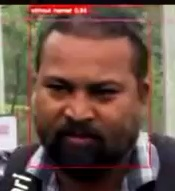

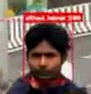

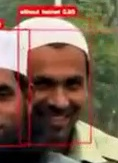

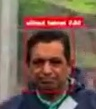

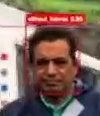

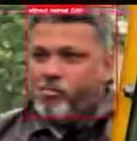

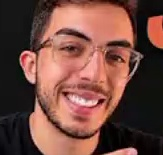

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:
import cv2, shutil
from pathlib import Path
from datetime import datetime
from ultralytics import YOLO
from google.colab import files
from IPython.display import Image, display

# ---------- الإعدادات ----------
WEIGHTS = "/content/runs/helmet_detector/weights/best.pt"
CONF = 0.5                      # نزّله لـ 0.3 إذا بيفوّت مخالفات
VIOLATION_KEYWORD = "without"   # كلمة بتميز كلاس "بدون خوذة"
OUT_DIR = Path("/content/violations")
# --------------------------------

model = YOLO(WEIGHTS)
violation_ids = [i for i, n in model.names.items()
                 if VIOLATION_KEYWORD in n.lower() and not n.lower().startswith("with ")]
assert violation_ids, f"ما لقيت كلاس مطابق. الكلاسات: {model.names}"
print("كلاس المخالفة:", {i: model.names[i] for i in violation_ids})

# ارفع الفيديو
uploaded = files.upload()
video_path = f"/content/{list(uploaded.keys())[0]}"

if OUT_DIR.exists():
    shutil.rmtree(OUT_DIR)
OUT_DIR.mkdir(parents=True)

saved_ids = set()   # صورة وحدة لكل سائق
count = 0

for r in model.track(source=video_path, stream=True, persist=True, conf=CONF, verbose=False):
    if r.boxes is None or len(r.boxes) == 0:
        continue
    frame = r.orig_img
    annotated = r.plot()
    ids = r.boxes.id.int().tolist() if r.boxes.id is not None else [None] * len(r.boxes)

    for box, tid in zip(r.boxes, ids):
        if int(box.cls) not in violation_ids:
            continue
        if tid is not None and tid in saved_ids:
            continue
        if tid is not None:
            saved_ids.add(tid)

        count += 1
        stamp = datetime.now().strftime("%H%M%S_%f")
        x1, y1, x2, y2 = map(int, box.xyxy[0])
        pad = 20
        crop = frame[max(0, y1 - pad):y2 + pad, max(0, x1 - pad):x2 + pad]
        cv2.imwrite(str(OUT_DIR / f"{count:03d}_{stamp}_full.jpg"), annotated)
        if crop.size:
            cv2.imwrite(str(OUT_DIR / f"{count:03d}_{stamp}_crop.jpg"), crop)

print(f"\nعدد المخالفين المكتشفين: {count}")
for p in sorted(OUT_DIR.glob("*_crop.jpg")):
    display(Image(str(p), width=300))

# تحميل كل الصور كملف zip
if count:
    shutil.make_archive("/content/violations", "zip", OUT_DIR)
    files.download("/content/violations.zip")